# 2. QCNN v2: más expresividad con la misma lectura

v1 no aprendió (notebook 01). v2 conserva los datos, los 10 qubits, la pirámide 10 → 8 → 4 y la lectura por probabilidades, y cambia solo el circuito y la capa de entrada para darle más capacidad. Si el cuello de botella fuera la expresividad, v2 debería mejorar con claridad.

El protocolo (datos, optimizador, semillas, métrica) es el del notebook 01.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

from qcnn_mnist import figuras
from qcnn_mnist import resultados as res

figuras.aplicar_estilo()
R = res.cargar()   # modelo -> resultados por semilla (results/<modelo>/semilla_<s>.json)
S = res.resumen(R) # modelo -> media y desviación entre semillas

## Qué cambia respecto de v1

| | v1 | v2 |
| --- | --- | --- |
| Rotación de las convoluciones | $R_Y(\theta)$, 1 ángulo por qubit | $\mathrm{Rot}(\phi, \theta, \omega)$, rotación SU(2) general, 3 ángulos |
| *Data re-uploading* | No | Tras el primer pooling, cada superviviente vuelve a recibir $R_Y$ con el ángulo de su parche |
| Bias de la capa de entrada | Fijo | Entrenable |
| Penalización de *ghost states* | λ = 0,3 | λ = 0,1 |
| Parámetros | 26 | 64 |

El *re-uploading* vuelve a inyectar el dato después de que la primera convolución y el pooling lo hayan mezclado, una técnica habitual para aumentar la expresividad de circuitos pequeños. La λ menor reduce el peso del término que empuja la probabilidad fuera de los estados sobrantes, para que la pérdida se concentre en la clase correcta.

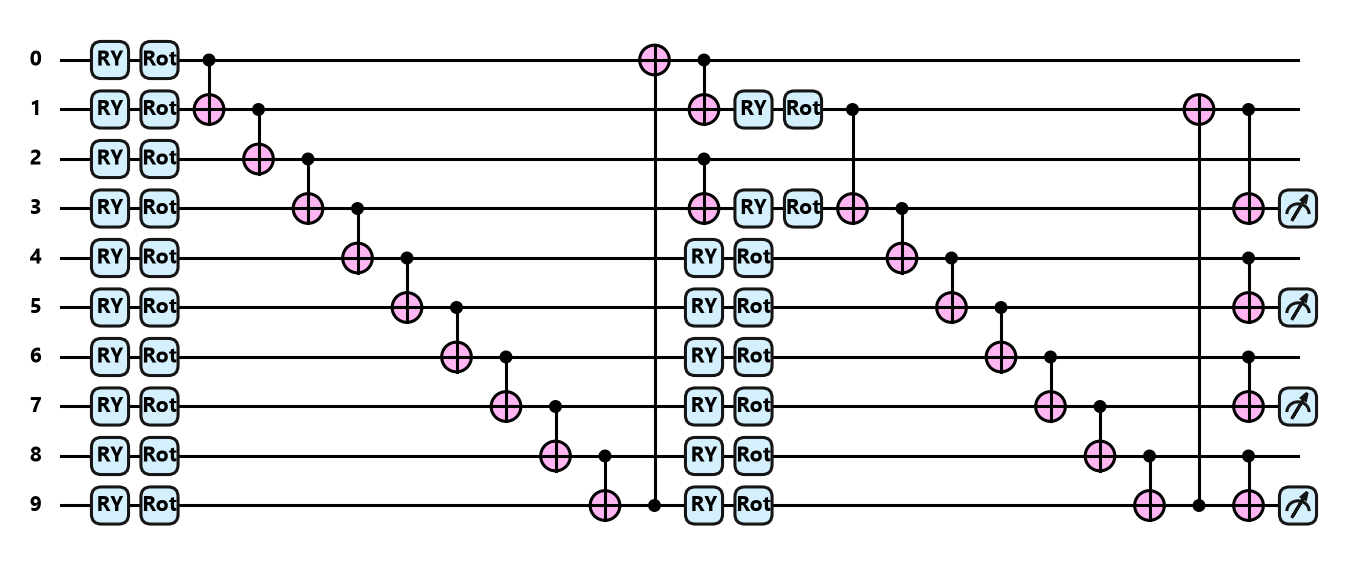

Parámetros entrenables: v1 26, v2 64


In [2]:
fig = figuras.circuito("qcnn_v2")
figuras.guardar(fig, "02_circuito_v2")
plt.show()
print(f"Parámetros entrenables: v1 {S['qcnn_v1'].n_parametros}, v2 {S['qcnn_v2'].n_parametros}")

## Resultados

In [3]:
display(Markdown(res.tabla_markdown(S, ["qcnn_v1", "qcnn_v2", "cnn_10", "cpn_10"])))

| Modelo | Parámetros | Accuracy de prueba (%) | Accuracy de entrenamiento (%) | Cómputo (h) |
| --- | ---: | ---: | ---: | ---: |
| QCNN v1 | 26 | 15,1 ± 10,7 | 15,3 ± 10,4 | 0,06 |
| QCNN v2 | 64 | 23,1 ± 4,6 | 22,2 ± 4,3 | 0,07 |
| CNN 10×10 | 225 | 59,9 ± 4,4 | 60,9 ± 4,3 | 0,01 |
| CPN 10×10 | 78 | 46,9 ± 0,8 | 46,9 ± 1,3 | 0,01 |

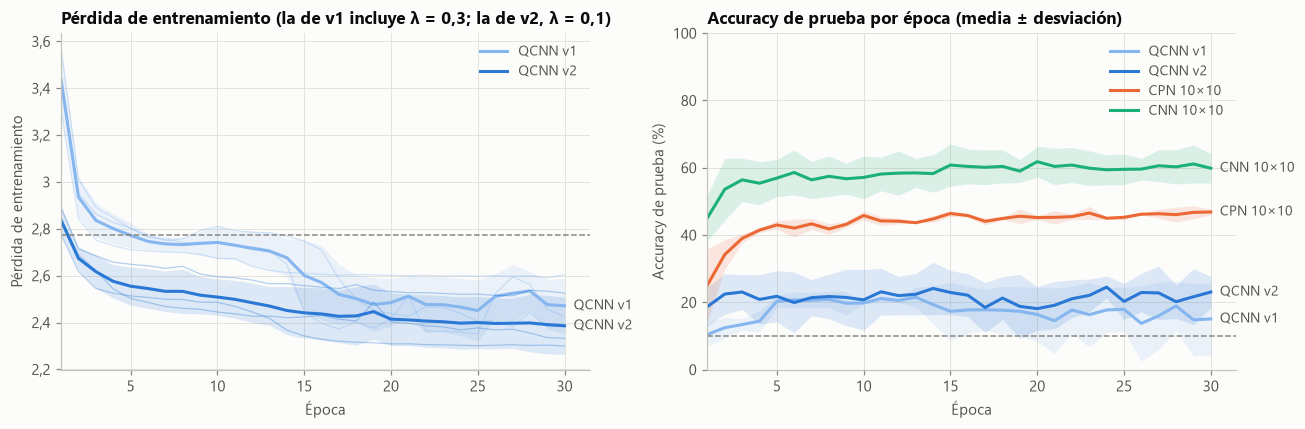

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
figuras.curvas(ax1, R, ["qcnn_v1", "qcnn_v2"], "perdida_train")
ax1.axhline(np.log(16), color=figuras.TINTA_TENUE, linestyle="--", linewidth=1)
ax1.set_title("Pérdida de entrenamiento (la de v1 incluye λ = 0,3; la de v2, λ = 0,1)")
figuras.curvas(ax2, R, ["qcnn_v1", "qcnn_v2", "cpn_10", "cnn_10"], "acc_test_por_epoca", semillas=False)
ax2.axhline(100 * figuras.AZAR, color=figuras.TINTA_TENUE, linestyle="--", linewidth=1)
ax2.set_ylim(0, 100)
ax2.set_title("Accuracy de prueba por época (media ± desviación)")
fig.tight_layout()
figuras.guardar(fig, "02_curvas_v1_v2")
plt.show()

Semilla 42: accuracy final 20,4 %, clases nunca predichas: [6, 7, 8], clase más predicha 3 (283 de 500)
Semilla 43: accuracy final 28,4 %, clases nunca predichas: [], clase más predicha 1 (127 de 500)
Semilla 44: accuracy final 20,4 %, clases nunca predichas: [0, 8, 9], clase más predicha 3 (240 de 500)


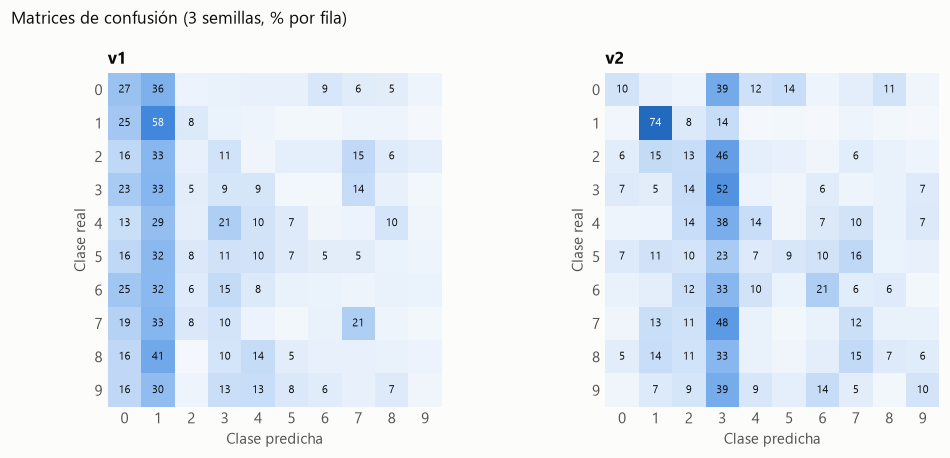

In [5]:
for c in R["qcnn_v2"]:
    predichas = np.array(c["matriz_confusion"]).sum(0)
    print(
        f"Semilla {c['semilla']}: accuracy final {res.pct(c['acc_test'])} %, "
        f"clases nunca predichas: {np.flatnonzero(predichas == 0).tolist()}, "
        f"clase más predicha {predichas.argmax()} ({predichas.max()} de {predichas.sum()})"
    )

fig, ejes = plt.subplots(1, 2, figsize=(9.2, 4.2))
figuras.confusion(ejes[0], R["qcnn_v1"], "v1")
figuras.confusion(ejes[1], R["qcnn_v2"], "v2")
fig.suptitle("Matrices de confusión (3 semillas, % por fila)", x=0.01, ha="left", fontsize=11)
fig.tight_layout()
figuras.guardar(fig, "02_confusion_v1_v2")
plt.show()

## Lectura

- **v2 mejora sobre v1, pero poco.** La accuracy sube y la variación entre semillas baja, aunque el modelo sigue lejos de los dos controles clásicos con los mismos parches, incluida la CPN, de tamaño parecido.
- **El patrón de errores se mantiene.** Las predicciones se concentran en pocas clases y algunas clases no se predicen nunca en ciertas semillas.
- **Más expresividad no basta con esta lectura.** Multiplicar los parámetros del circuito y reinyectar el dato no resuelve el problema principal. Queda como hipótesis más fuerte la lectura: asignar cada clase a un estado base fijo obliga al circuito a llevar cada dígito a una región concreta de un espacio de 16 estados, sin ninguna capa que pueda adaptar esa correspondencia. El notebook 03 sustituye esa lectura por valores esperados ⟨Z⟩ seguidos de una capa lineal.